# Systematic Literature Review — Data Processing Pipeline

This notebook processes results from database searches (ACM, Scopus, WoS, IEEE Xplore), deduplicates them, applies quality rankings, filters by venue quality, and exports results for screening.

## 1. Configuration

In [ ]:
import os
import sys

import numpy as np
import pandas as pd

# Add the project root to the path so litreview can be imported:
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from litreview import loaders, ranking, analysis
from litreview.utils.normalization import normalize_doi, normalize_title
from litreview.utils.deduplication import find_doi_duplicates, TitleMatcher

Using rapidfuzz for fuzzy string matching.


In [4]:
# --- Paths ---
data_dir = os.path.join(project_root, "notebooks", "data")
results_dir = os.path.join(data_dir, "databases_search_results")
csv_dir = os.path.join(data_dir, "databases_search_results")
ranks_dir = os.path.join(data_dir, "ranks")
output_dir = data_dir  # output files go alongside the data

# --- Parameters ---
# Set to True to load from pre-exported CSVs (faster); False to re-parse .bib files
use_cached_csv = False

# Raw database export file paths (only used when process_bib_files=True)
file_paths = {
    "ACM Digital Library": os.path.join(results_dir, "acm_query_results.bib"),
    "Scopus": os.path.join(results_dir, "scopus_query_results.bib"),
    "WoS": os.path.join(results_dir, "wos_query_results.bib"),
    "IEEE Xplore": os.path.join(results_dir, "ieee_query_results.bib"),
}

# Fuzzy title matching threshold (0-100)
title_match_threshold = 90

## 2. Load Data

In [6]:
all_results = loaders.load_all_databases(
    file_paths,
    use_cached_csv=use_cached_csv,
    # csv_dir=csv_dir,
)

ACM Digital Library finished! (1360 records)
Scopus finished! (8915 records)
WoS finished! (670 records)
IEEE Xplore finished! (2369 records)

Total records loaded: 13314


In [7]:
print(f"Shape: {all_results.shape}")
print(f"\nRecords per database:")
display(all_results["Database"].value_counts())
all_results.sample(3)

Shape: (13314, 16)

Records per database:


Database
Scopus                 8915
IEEE Xplore            2369
ACM Digital Library    1360
WoS                     670
Name: count, dtype: int64

,Title,Authors,Year,Abstract,DOI,ISSN,ISBN,Source title,Journal,Book title,Publisher,Series,Author Keywords,Keywords,Entry Type,Database
4444,Towards Faithful Multi-step Reasoning through ...,"Chu, Zheng and Chen, Jingchang and Wang, Zhong...",2025,Despite the remarkable reasoning capabilities ...,,29512093,979-889176196-4,Proceedings - International Conference on Comp...,Proceedings - International Conference on Comp...,,Association for Computational Linguistics (ACL),,Benchmarking; Coarse-grained modeling; Causal ...,Benchmarking; Coarse-grained modeling; Causal ...,conference,Scopus
5712,RUBRA: An Agentic AI System for Automatic Shor...,"Haldar, Subhajit and Sengupta, Souvik and Das,...",2025,The proliferation of deep Learning application...,10.1109/CIACON65473.2025.11189329,,979-833154411-9,"International Conference on Computing, Intelli...","International Conference on Computing, Intelli...",,Institute of Electrical and Electronics Engine...,,Computation theory; Computer aided instruction...,Computation theory; Computer aided instruction...,conference,Scopus
9504,GridHTM: Grid-Based Hierarchical Temporal Memo...,"Monakhov, Vladimir and Thambawita, Vajira and ...",2023,The interest in video anomaly detection system...,10.3390/s23042087,14248220,,Sensors,Sensors,,MDPI,,Complex networks; Deep learning; E-learning; G...,Complex networks; Deep learning; E-learning; G...,article,Scopus


In [8]:
all_results.to_csv(os.path.join(output_dir, "all_initial_results_combined.csv"), index=False)

## 3. Deduplication

In [8]:
processed_results = all_results.copy()

# Normalize DOIs and titles
processed_results["normalised_doi"] = processed_results["DOI"].astype(str).apply(normalize_doi)
processed_results["normalised_title"] = processed_results["Title"].apply(normalize_title)

print(f"Total records before deduplication: {len(processed_results)}")

Total records before deduplication: 13314


### 3.1 DOI-based deduplication

In [9]:
# Detect DOI duplicates
doi_groups = find_doi_duplicates(
    processed_results[~processed_results["DOI"].isna()].to_dict(orient="records")
)
print(f"DOI duplicate groups found: {len(doi_groups)}")

# Show group size distribution
lengths = pd.Series([len(g) for g in doi_groups])
display(pd.DataFrame({
    "Group Size": lengths.value_counts().sort_index().index,
    "Count": lengths.value_counts().sort_index().values,
}))

DOI duplicate groups found: 1194


,Group Size,Count
0,2,1061
1,3,133


In [10]:
# Remove DOI-based duplicates
initial_size = len(processed_results)

has_doi = processed_results[~processed_results["normalised_doi"].isna()]
no_doi = processed_results[processed_results["normalised_doi"].isna()]

has_doi_dedup = has_doi.drop_duplicates(subset="normalised_doi", keep="first")
processed_results = pd.concat([has_doi_dedup, no_doi])

print(f"Removed {initial_size - len(processed_results)} duplicates based on DOI.")
print(f"Remaining records: {len(processed_results)}")

Removed 1327 duplicates based on DOI.
Remaining records: 11987


### 3.2 Title-based fuzzy deduplication

In [11]:
# Detect title duplicates using fuzzy matching
title_matcher = TitleMatcher(threshold=title_match_threshold)
title_groups = title_matcher.find_duplicates(processed_results.to_dict(orient="records"))

print(f"Title duplicate groups found: {len(title_groups)}")

for i, group in enumerate(title_groups, 1):
    print(f"\n  Group {i}: {len(group)} records (confidence: {title_matcher.get_confidence(group):.3f})")
    for record in group:
        print(f"    - {record['Title']} (DOI: {record['DOI']})")

Title duplicate groups found: 157

  Group 1: 3 records (confidence: 1.000)
    - Counterfactual explanations for models of code (DOI: 10.1145/3510457.3513081)
    - Counterfactual Explanations for Models of Code (DOI: 10.18420/sw2024_27)
    - Counterfactual Explanations for Models of Code (DOI: 10.1109/ICSE-SEIP55303.2022.9794112)

  Group 2: 2 records (confidence: 0.905)
    - Assured Offline LLM-Based Software Engineering (DOI: 10.1145/3643661.3643953)
    - Assured LLM-Based Software Engineering (DOI: )

  Group 3: 2 records (confidence: 0.966)
    - Do Machines and Humans Focus on Similar Code? Exploring Explainability of Large Language Models in Code Summarization (DOI: 10.1145/3643916.3644434)
    - {Do Machines and Humans Focus on Similar Code? Exploring Explainability of Large Language Models in Code Summarization} (DOI: )

  Group 4: 2 records (confidence: 0.988)
    - Unity Is Strength: Collaborative LLM-Based Agents for Code Reviewer Recommendation (DOI: 10.1145/3691620.36

In [12]:
# Remove title-based duplicates (keep first of each pair)
initial_count = len(processed_results)

repeated_titles = [group[0]["normalised_title"] for group in title_groups]
count_not_processed = 0

for title in repeated_titles:
    duplicate_rows = processed_results[processed_results["normalised_title"] == title]
    if len(duplicate_rows) >= 2:
        indices_to_drop = duplicate_rows.index[1:]
        processed_results = processed_results.drop(indices_to_drop)
    else:
        count_not_processed += 1
        print(f"=> Expected 2 or more rows for '{title}', found {len(duplicate_rows)}. Skipping.")

rows_dropped = initial_count - len(processed_results)
print(f"\nRows dropped: {rows_dropped}")
print(f"Titles not auto-processed: {count_not_processed}")
print(f"Remaining records: {len(processed_results)}")

=> Expected 2 or more rows for 'assured offline llm-based software engineering', found 1. Skipping.
=> Expected 2 or more rows for 'do machines and humans focus on similar code? exploring explainability of large language models in code summarization', found 1. Skipping.
=> Expected 2 or more rows for 'unity is strength: collaborative llm-based agents for code reviewer recommendation', found 1. Skipping.
=> Expected 2 or more rows for 'redundancy and concept analysis for code-trained language models', found 1. Skipping.
=> Expected 2 or more rows for 'explainable feature engineering in health data science: empirical comparison of chatgpt-4o and classical machine learning methods', found 1. Skipping.
=> Expected 2 or more rows for 'unraveling the influence of training data and internal structures in large language models for enhanced explainability', found 1. Skipping.
=> Expected 2 or more rows for 'df-rag: a dual federated retrieval-augmented generation framework for collaborative medi

## 4. Rank & Filter by Venue Quality

In [16]:
ranking_data = ranking.load_ranking_data(ranks_dir)

Loaded ranking data from /Users/mafaldasavelho/Documents/Faculty/RS III/repos/llms_for_xai_lit_review/notebooks/data/ranks:
  CORE conferences 2023: 956 entries
  CORE journals 2020:    639 entries
  SciMago 2022:          31297 entries
  SciMago 2023:          31283 entries
  SciMago 2024:          31136 entries
  Predatory journals:    2780 entries
  Predatory publishers:  1363 entries


In [17]:
processed_results = ranking.apply_rankings(
    processed_results,
    ranking_data,
    enrich_venues=True,
    core_fuzzy_threshold=85,
    rank_strategy="latest"  # alternatives: "publication_year"
)

pyalex imported successfully for OpenAlex enrichment.
No records with missing venue and valid DOI found for OpenAlex enrichment.
Building ranking lookup indices...
Applying rankings to 11838 records...


In [18]:
# Inspect ranking distribution
print("CORE Conference ranks:")
display(processed_results["is_core_conference_A*_A_B"].value_counts())

print("\nCORE Journal ranks:")
display(processed_results["is_core_journal_A*_A_B"].value_counts())

print("\nSciMago 2022:")
display(processed_results["is_scimago_q1_q2_2022"].value_counts())

print("\nSciMago 2023:")
display(processed_results["is_scimago_q1_q2_2023"].value_counts())

print("\nSciMago 2024:")
display(processed_results["is_scimago_q1_q2_2024"].value_counts())

print("\nPredatory journals:")
display(processed_results["is_predatory_journal_2025"].value_counts())

print("\nPredatory publishers:")
display(processed_results["is_predatory_publisher_2025"].value_counts())

CORE Conference ranks:


is_core_conference_A*_A_B
                                           8431
A*                                         1009
B                                           745
C                                           690
A                                           390
National:Slovakia                           292
Australasian B                              151
TBR                                          24
National: USA                                20
Journal Published                            11
Regional: Austria, Germany, Netherlands       8
National: China                               7
National                                      7
National:Morocco                              6
Australasian C                                5
Unranked                                      5
National: India                               4
National: Russia                              4
National: Korea                               3
National: Pakistan                            3
unranked      


CORE Journal ranks:


is_core_journal_A*_A_B
                    10693
B                     439
A*                    308
A                     261
C                     110
not primarily CS       16
Not primarily CS       11
Name: count, dtype: int64


SciMago 2022:


is_scimago_q1_q2_2022
    11838
Name: count, dtype: int64

... (4 outputs left out)


Predatory journals:


is_predatory_journal_2025
                                                11312
Sensors                                            41
Frontiers in Artificial Intelligence               38
Mathematics                                        27
Big Data and Cognitive Computing                   21
                                                ...  
Micromachines                                       1
Heritage                                            1
Frontiers in Neuroscience                           1
International Journal of Intelligent Systems        1
AI                                                  1
Name: count, Length: 139, dtype: int64


Predatory publishers:


is_predatory_publisher_2025
                                                         11240
Multidisciplinary Digital Publishing Institute (MDPI)      589
Engineering and Technology Publishing                        5
IGI Global                                                   2
Premier Science                                              1
Sciedu Press                                                 1
Name: count, dtype: int64

In [19]:
# Filter to keep only Q1/Q2 (SciMago) or A*/A/B (CORE)
final_results, excluded_papers = ranking.filter_by_quality(processed_results)

Force-kept 14 included studies that did not meet venue quality criteria.
Papers after quality filtering: 7099
Dropped 4739 papers not in ranked venues.


In [22]:
# Save filtered results
# output_path = os.path.join(output_dir, "final_results_for_screening.csv")
# final_results.to_csv(output_path, index=False)
# print(f"Saved {len(final_results)} papers to {output_path}")

# Save excluded papers
# excluded_path = os.path.join(output_dir, "excluded_from_screening.csv")
# excluded_papers.to_csv(excluded_path, index=False)
# print(f"Saved {len(excluded_papers)} excluded papers to {excluded_path}")

In [23]:
# Read previously saved filtered results:
output_path = os.path.join(output_dir, "final_results_for_screening.csv")
final_results = pd.read_csv(output_path)
print(f"Load {len(final_results)} papers for title + abstract screening {output_path}")

# Read previously saved excluded papers: 
# excluded_path = os.path.join(output_dir, "excluded_from_screening.csv")
# excluded_papers = pd.read_csv(excluded_path)
# print(f"Load {len(excluded_papers)} excluded papers {excluded_path}")

Load 7099 papers for title + abstract screening /Users/mafaldasavelho/Documents/Faculty/RS III/repos/llms_for_xai_lit_review/notebooks/data/final_results_for_screening.csv


## 5. Quantitative Analysis

<b>Note:</b> To avoid proliferating auxiliary files in the repository (DOI lists, external CSVs, text files), the final set of included studies in the qualitative analysis is hardcoded here. This cell serves as the single source of truth for the included studies list from this point on.

In [11]:
included_titles = [
    "Supporting Student Decisions on Learning Recommendations: An LLM-Based Chatbot with Knowledge Graph Contextualization for Conversational Explainability and Mentoring",
    "Zero-shot LLM-guided Counterfactual Generation: A Case Study on NLP Model Evaluation",
    "Knowledge Augmented Significant Language Model-Based Chatbot for Explainable Diabetes Mellitus Prediction",
    "It is not a piece of cake for GPT: Explaining Textual Entailment Recognition in the presence of Figurative Language",
    "LLaVA Needs More Knowledge: Retrieval Augmented Natural Language Generation with Knowledge Graph for Explaining Thoracic Pathologies",
    "Explaining Graph Neural Networks with Large Language Models: A Counterfactual Perspective on Molecule Graphs",
    "ArgMed-Agents: Explainable Clinical Decision Reasoning with LLM Discussion via Argumentation Schemes",
    "Adaptive and transparent decision-making in autonomous robots through graph-structured world models",
    "LLM in the Loop: A Framework for Contextualizing Counterfactual Segment Perturbations in Point Clouds",
    "ARTS: A General and Efficient Multi-Task Self-Prompt Framework for Explainable Sequential Recommendation",
    "\'What\'s Happening\' - A Human-centered Multimodal Interpreter Explaining the Actions of Autonomous Vehicles",
    "Towards Co-Constructed Explanations: A Multi-Agent Reasoning-Based Conversational System for Adaptive Explanations",
    "IMPACT: an interactive multi-disease prevention and counterfactual treatment system using explainable AI and a multimodal LLM",
    "The Fallacy of Explainable Generative AI: evidence from argumentative prompting in two domains",
    "Natural Language Explanations for Suicide Risk Classification Using Large Language Models",
    "Beyond Predictive Learning Analytics Modelling and onto Explainable Artificial Intelligence with Prescriptive Analytics and ChatGPT",
    "LLaMA-UTP: Knowledge-Guided Expert Mixture for Analyzing Uncertain Tax Positions",
    "From Feature Importance to Natural Language Explanations Using LLMs with RAG",
    "Natural Language Explanation for Autonomous Navigation",
    "Explingo: Explaining AI Predictions using Large Language Models",
    "Mind the gap: from plausible to valid self-explanations in large language models",
    "Automated vehicle fault diagnosis and report generation using hybrid machine learning with multi-step RAG approach",
    "Explainable depression symptom detection in social media",
    "A prompt framework for enhancing LLM-based explainability of medical machine learning models: an intensive care unit application",
    "LLiMe: enhancing text classifier explanations with large language models",
    "Tell me a story! Narrative-driven XAI with Large Language Models",
    "DialogueLLM: Context and emotion knowledge-tuned large language models for emotion recognition in conversations",
    "GraphXAIN: Narratives to Explain Graph Neural Networks",
    "Dialogue-Based XAI Approaches: Exploring the Continuum from Static Explanations to Free-Form Chat Interfaces",
    "Explain further: multi-level explanations for fake news detection using large language models",
    "AI-on-RAN for Cyber Defense: An XAI-LLM Framework for Interpretable Anomaly Detection",
    "KnowPath: An LLM-Supported Knowledge Graph Construction and Path Finding Framework to Explainable MOOC Recommendations",
    "Leveraging Large Language Models for Scalable and Explainable Cybersecurity Log Analysis",
    "OPG-SPELL: Visual and Textual Explanations That Influence Understanding of the AI Model for Sex Prediction From Orthopantomograms",
    "\"Detectors Lead, LLMs Follow\": Integrating LLMs and traditional models on implicit hate speech detection to generate faithful and plausible explanations",
    "From segmentation to explanation: Generating textual reports from MRI with LLMs",
    "Guiding LLMs to Generate High-Fidelity and High-Quality Counterfactual Explanations for Text Classification",
    "PneumoNet: Artificial Intelligence Assistance for Pneumonia Detection on X-Rays",
    "Conversational Explanations: Discussing Explainable AI with Non-AI Experts",
    "Explaining machine learning models with interactive natural language conversations using TalkToModel",
    "Adapting LLMs for Personalized Evaluation of Explanations for Recommendations: A Meta-Learning Approach based on MAML",
    "\"show Me How\": Benefits and Challenges of Agent-Augmented Counterfactual Explanations for Non-Expert Users",
    "ECHO: Enhancing Conversational Explainable AI through Tool-Augmented Language Models",
    "TARGE: large language model-powered explainable hate speech detection",
    "Exploring Fairness and Explainability in LLM-Generated Support for Online Learning Discussion Forums",
    "Enhancing LLM-based clinical reasoning in anesthesiology via graph-augmented retrieval and explainable generation",
    "LatentExplainer: Explaining Latent Representations in Deep Generative Models with Multimodal Large Language Models",
    "CARAG: A Context-Aware Retrieval Framework for Fact Verification, Integrating Local and Global Perspectives of Explainable AI",
    "EnergiQ: A Prescriptive Large Language Model-Driven Intelligent Platform for Interpreting Appliance Energy Consumption Patterns",
    "Large Language Model XAI approach for illicit activity Investigation in Bitcoin",
]

included_studies = pd.DataFrame({"Title": included_titles})

# Enrich included_studies with metadata from the ASReview-relevant CSV:
final_results_screening = pd.read_csv(os.path.join(data_dir, "processed/asreview_relevant_final_results_for_qa_phase.csv"))

final_results_screening["_norm"] = final_results_screening["Title"].apply(normalize_title)
included_studies["_norm"] = included_studies["Title"].apply(normalize_title)

extra_cols = [c for c in final_results_screening.columns if c not in {"Title", "_norm"}]

fuzzy_matcher = TitleMatcher(threshold=85)
enriched_rows = []
not_matched = []

for _, row in included_studies.iterrows():
    match = final_results_screening[final_results_screening["_norm"] == row["_norm"]]

    if len(match) > 0:
        enriched_rows.append({**row.to_dict(), **match.iloc[0][extra_cols].to_dict()})
        continue

    # Fallback: Fuzzy match
    best_score, best_idx = 0, None
    for idx, candidate in final_results_screening["Title"].items():
        score = fuzzy_matcher._similarity(row["Title"], candidate)
        if score > best_score:
            best_score, best_idx = score, idx

    if best_score >= 85:
        fallback_row = final_results_screening.loc[best_idx]
        fallback_vals = {c: fallback_row.get(c, np.nan) for c in extra_cols}
        enriched_rows.append({**row.to_dict(), **fallback_vals})
    else:
        not_matched.append(row["Title"])
        enriched_rows.append(row.to_dict())

included_studies = pd.DataFrame(enriched_rows).drop(columns=["_norm"])
final_results_screening = final_results_screening.drop(columns=["_norm"])

if not_matched:
    print(f"\nWARNING: {len(not_matched)} title(s) could not be matched:")
    for t in not_matched:
        print(f"  - {t}")

print(f"Total studies: {len(included_studies)}")
print(f"\nYear distribution:\n{included_studies['Year'].value_counts().sort_index()}")

included_studies.head()


Total studies: 50

Year distribution:
Year
2023     1
2024    12
2025    31
2026     6
Name: count, dtype: int64


,Title,Unnamed: 0,Authors,Year,Abstract,DOI,ISSN,ISBN,Source title,Journal,...,is_scimago_q1_q2_2024,is_predatory_journal_2025,is_predatory_publisher_2025,scimago_2022_area,scimago_2024_area,scimago_2023_area,Unnamed: 28,asreview_label,asreview_time,asreview_note
0,Supporting Student Decisions on Learning Recom...,1640,"Abu-Rasheed, Hasan and Abdulsalam, Mohamad Hus...",2024,Student commitment towards a learning recommen...,NaN,16130073,NaN,CEUR Workshop Proceedings,CEUR Workshop Proceedings,...,-,NaN,NaN,NaN,Computer Science,NaN,NaN,1,2026-01-18 20:19:14,NaN
1,Zero-shot LLM-guided Counterfactual Generation...,57,"Bhattacharjee, Amrita and Moraffah, Raha and G...",2024,With the development and proliferation of larg...,10.1109/BigData62323.2024.10825537,26391589,979-835036248-0,Proceedings - 2024 IEEE International Conferen...,Proceedings - 2024 IEEE International Conferen...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2026-01-18 20:34:23,NaN
2,Knowledge Augmented Significant Language Model...,986,"Elfayoumi, Mazen and AbouElazm, Mohamed and Mo...",2025,This study proposes an innovative diabetes pre...,10.1109/IMCOM64595.2025.10857525,NaN,979-833150781-7,Proceedings of the 2025 19th International Con...,Proceedings of the 2025 19th International Con...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2026-01-18 20:19:58,NaN
3,It is not a piece of cake for GPT: Explaining ...,1949,"Gallipoli, Giuseppe and Cagliero, Luca",2025,Textual Entailment Recognition (TER) aims to p...,NaN,29512093,979-889176196-4,Proceedings - International Conference on Comp...,Proceedings - International Conference on Comp...,...,-,NaN,NaN,NaN,Computer Science; Mathematics,NaN,NaN,1,2026-01-18 20:20:24,NaN
4,LLaVA Needs More Knowledge: Retrieval Augmente...,578,"Hamza, Ameer and Abdullah and Ahn, Yong Hyun a...",2025,Generating Natural Language Explanations (NLEs...,10.1609/aaai.v39i3.32342,21595399,NaN,Proceedings of the AAAI Conference on Artifici...,Proceedings of the AAAI Conference on Artifici...,...,-,NaN,NaN,NaN,Computer Science,NaN,NaN,1,2026-01-18 18:50:53,NaN


### 5.1 Visualizations on the 152 ASReview-relevant studies

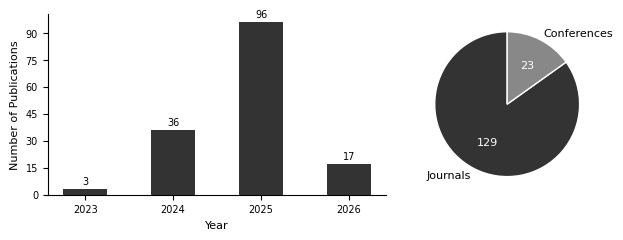

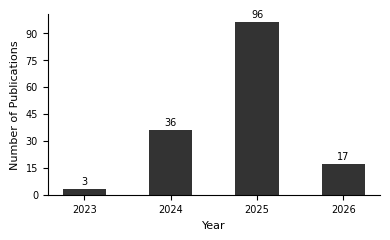

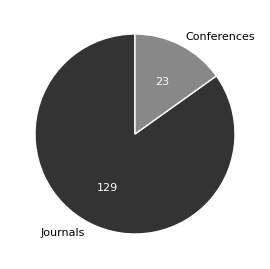

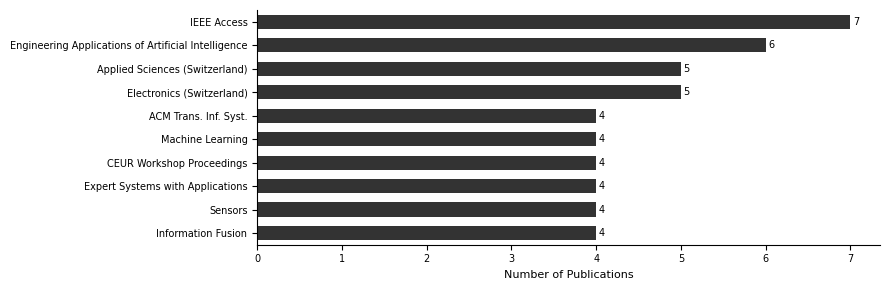

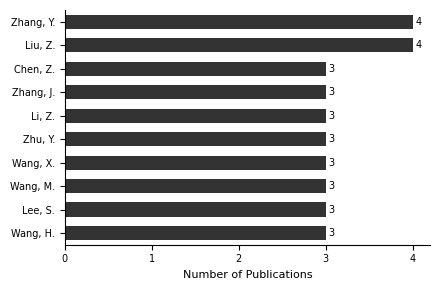

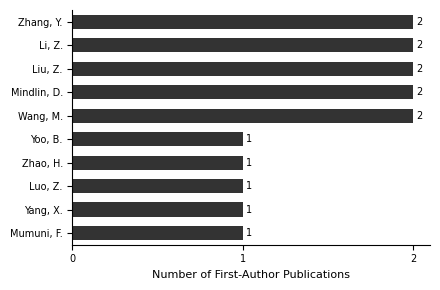

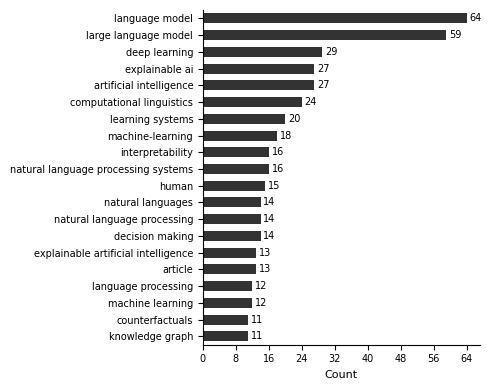

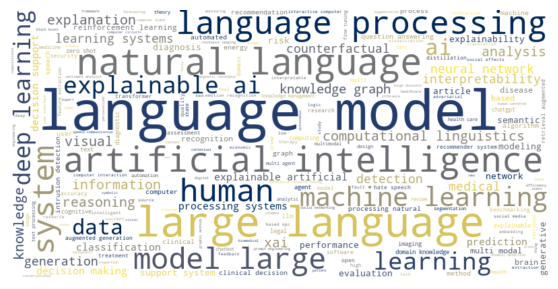

In [12]:
analysis.plot_year_and_venue(final_results_screening)
analysis.plot_year_distribution(final_results_screening)
analysis.plot_entry_type_distribution(final_results_screening)
analysis.plot_top_sources(final_results_screening)
analysis.plot_top_authors(final_results_screening)
analysis.plot_top_first_authors(final_results_screening)
analysis.plot_top_keywords(final_results_screening)
analysis.plot_keyword_wordcloud(final_results_screening, colormap="cividis")

### 5.2 Visualizations on the 50 included studies

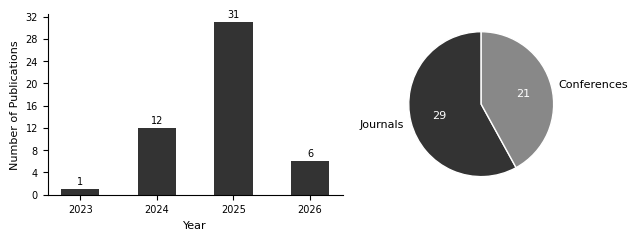

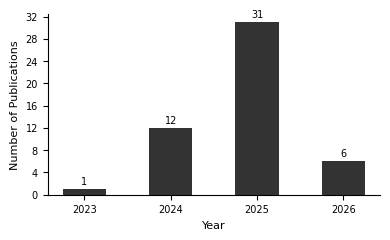

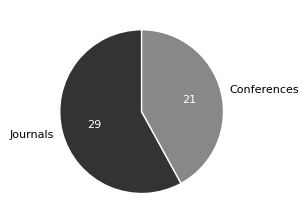

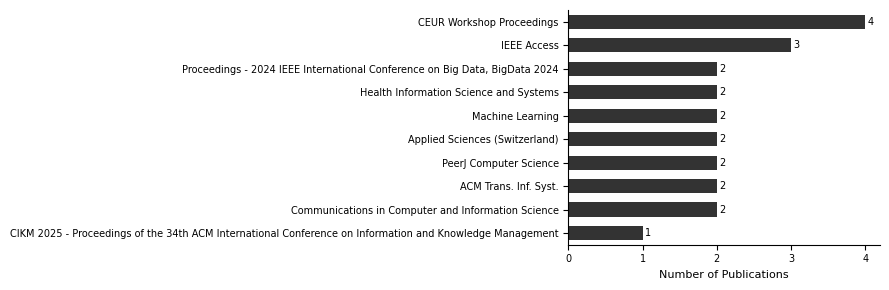

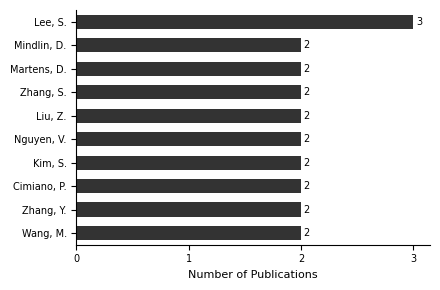

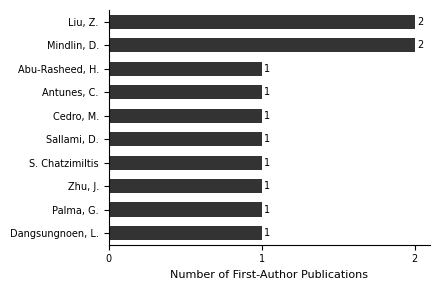

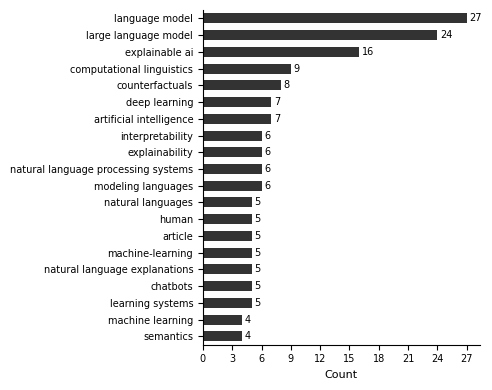

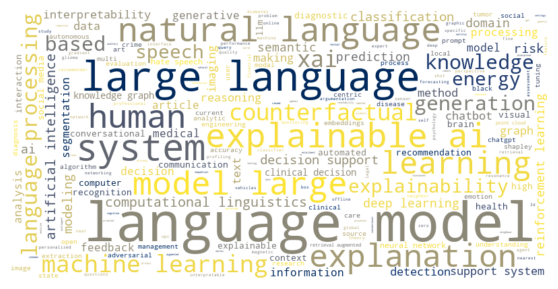

In [ ]:
analysis.plot_year_and_venue(included_studies)
analysis.plot_year_distribution(included_studies)
analysis.plot_entry_type_distribution(included_studies)
analysis.plot_top_sources(included_studies, figsize=(9,3))
analysis.plot_top_authors(included_studies)
analysis.plot_top_first_authors(included_studies)
analysis.plot_top_keywords(included_studies)
analysis.plot_keyword_wordcloud(included_studies, colormap="cividis")

### 5.3 Bibliometric tables on the 50 included studies

Tables built from the manually-curated `additional_data_for_quantitativ` sheet. Each table footer reports `n` and missingness against the 50-study corpus.

In [14]:
quant = loaders.load_quantitative_sheet(
    os.path.join(data_dir, "processed/data_form_extraction_and_qa_analysis_of_selected_papers.xlsx")
)

print(f"Loaded {len(quant)} rows × {quant.shape[1]} cols")
quant.head()

Loaded 50 rows × 12 cols


,Title,First Author,Venue,Country,Continent,Area,Keyword 1,Keyword 2,Keyword 3,SJR (2024),H-Index,CORE Ranking
0,Conversational Explanations: Discussing Explai...,"Zhang, T.",International Conference on Intelligent User I...,Singapore,Asia,HCI,Human-centered computing,Interactive systems and tools,Collaborative and social computing systems and...,NaN,NaN,A
1,ARTS: A General and Efficient Multi-Task Self-...,"Liu, Z.",ACM Transactions on Information Systems,China,Asia,Recommender Systems,Information systems,Recommender systems,NaN,1.540,100.0,NaN
2,Explaining Graph Neural Networks with Large La...,"He, Y.",Findings of the Association for Computational ...,United States,North America,Graph Networks,NaN,NaN,NaN,NaN,218.0,A*
3,Supporting Student Decisions on Learning Recom...,"Abu-Rasheed, H.",CEUR Workshop Proceedings,Germany,Europe,Recommender Systems,Chatbot,ChatGPT,Conversational explanations,NaN,NaN,NaN
4,LLiMe: enhancing text classifier explanations ...,"Angiulli, F.",Machine Learning,Italy,Europe,NLP,Black-box explanation,Explainable AI,Large language models,1.147,175.0,NaN


In [15]:
analysis.missing_values_overview(quant, output="dataframe")

Missingness overview — n = 50 of 50 (0% missing)


,Column,Non-null,Missing,% complete
0,Title,50,0,100.0
1,First Author,50,0,100.0
2,Venue,50,0,100.0
3,Country,50,0,100.0
4,Continent,50,0,100.0
5,Area,50,0,100.0
6,Keyword 1,48,2,96.0
7,Keyword 2,47,3,94.0
8,Keyword 3,46,4,92.0
9,SJR (2024),28,22,56.0


In [16]:
analysis.country_distribution(quant, top_n=25, output="dataframe")

Country distribution — n = 50 of 50 (0% missing)


,Country,Count,%
0,United States,10,20.0
1,China,5,10.0
2,Germany,4,8.0
3,Italy,4,8.0
4,Belgium,4,8.0
5,United Kingdom,3,6.0
6,Republic of Korea,3,6.0
7,New Zealand,2,4.0
8,Sweden,2,4.0
9,Malaysia,1,2.0


In [17]:
analysis.continent_distribution(quant, output="dataframe")

Continent distribution — n = 50 of 50 (0% missing)


,Continent,Count,%
0,Europe,23,46.0
1,Asia,13,26.0
2,North America,11,22.0
3,Oceania,2,4.0
4,Africa,1,2.0


In [18]:
analysis.area_distribution(quant, top_n=50, output="dataframe")

Area distribution (multi-label; % over mentions) — n = 50 of 50 (0% missing)


,Area,Count,%
0,Healthcare,10,18.9
1,NLP,8,15.1
2,Graph Networks,5,9.4
3,Autonomous Systems,5,9.4
4,HCI,4,7.5
5,Social Media & NLP,4,7.5
6,Machine Learning,4,7.5
7,Recommender Systems,3,5.7
8,Cybersecurity,3,5.7
9,Education,3,5.7


In [19]:
from IPython.display import display

kw = analysis.keyword_distribution(
    quant, top_n=10, keyword_level="both", output="dataframe"
)
for table in kw.values():
    display(table)

Keyword hierarchy distribution — n = 48 of 50 (4% missing)
Most-specific keyword distribution — n = 48 of 50 (4% missing)


,Keyword hierarchy,Count,%
0,Human-centered computing → Interactive systems...,1,2.1
1,Information systems → Recommender systems,1,2.1
2,explainability → fallacy → GPT4,1,2.1
3,Deep learning → Text processing → Tuning,1,2.1
4,Cryptocurrency → Financial cybercrime → LLMs,1,2.1
5,cybersecurity → explainability → interpretability,1,2.1
6,anomaly detection → appliance-level energy pro...,1,2.1
7,Attention-based explainability → Counterfactua...,1,2.1
8,Explainable Artificial Intelligence → Fake New...,1,2.1
9,explainable AI → large language models → menta...,1,2.1


,Keyword (most specific),Count,%
0,Large Language Models,3,6.2
1,Large language models,2,4.2
2,large language models,2,4.2
3,Explainable AI,2,4.2
4,LLMs,2,4.2
5,interpretability,2,4.2
6,Explainable machine learning,1,2.1
7,Large language model,1,2.1
8,GPT4,1,2.1
9,Tuning,1,2.1


In [20]:
analysis.venue_quality_summary(quant, output="dataframe")

Venue quality summary — n = 50 of 50 (0% missing)


,Metric,n,Median,IQR,Min,Max,Missing,% missing
0,SJR (2024),28,0.86,0.718–1.147,0.133,5.876,22,44.0
1,H-Index,29,107.00,68.0–186.0,21.000,290.000,21,42.0


In [21]:
analysis.core_ranking_distribution(quant, output="dataframe")

CORE ranking distribution — n = 10 of 50 (80% missing)


,CORE Ranking,Count,%
0,A*,2,20.0
1,A,4,40.0
2,B,4,40.0


In [24]:
analysis.top_venues_by_sjr(
    quant,
    top_n=50,
    include_h_index=True,
    order_by_num_papers=True,
    order_by_h_index=False,
    output="dataframe",
)

Top venues by number of papers — n = 50 of 50 (0% missing)


,Venue,Papers,SJR (2024),H-Index
0,CEUR Workshop Proceedings,4,NaN,NaN
1,IEEE Access,3,0.849,290.0
2,ACM Transactions on Information Systems,2,1.540,100.0
3,Machine Learning,2,1.147,175.0
4,Health Information Science and Systems,2,0.860,40.0
5,PeerJ Computer Science,2,0.719,59.0
6,Applied Sciences,2,0.521,162.0
7,CIKM - Proceedings of the ACM International Co...,2,NaN,NaN
8,Communications in Computer and Information Sci...,2,NaN,NaN
9,"IEEE International Conference on Big Data, Big...",2,NaN,NaN


## Additional Code to Address Manuscript Reviews

### Keyword co-occurrence network

To replace the word cloud, the enriched `included_studies.bib` file is converted into a keyword co-occurrence network. Nodes represent keywords and links represent the number of included studies in which two keywords occur together. The resulting JSON file follows the VOSviewer format and can be uploaded to VOSviewer Online to create the revised plot.

In [8]:
from collections import Counter
from itertools import combinations
from pathlib import Path
import json
import re

import bibtexparser

KEYWORD_ALIASES = {
    # LLM terminology
    'large language model': 'large language models',
    'llm': 'large language models',
    'llms': 'large language models',

    # Direct XAI label variants only
    'xai': 'explainable ai',
    'explainable artificial intelligence': 'explainable ai',
    'explainable ai (xai)': 'explainable ai',

    # Generative AI terminology
    'generative ai': 'generative ai (genai)',
    'genai': 'generative ai (genai)',

    # Conversational XAI
    'conversational explanation': 'conversational xai',
    'conversational explanations': 'conversational xai',
    'dialog-based xai': 'conversational xai',
    'dialogue-based xai': 'conversational xai',

    # Multi-agent systems: spelling variants only
    'multi-agent system': 'multi-agent systems',
    'multi agent systems': 'multi-agent systems',

    # Counterfactual explanations
    'counterfactual': 'counterfactual explanations',
    'counterfactuals': 'counterfactual explanations',
    'counterfactual explanation': 'counterfactual explanations',
    'counterfactual generation': 'counterfactual explanations',

    # Natural-language explanation formats
    'narrative explanation': 'natural language explanations',
    'narrative explanations': 'natural language explanations',
    'natural language explanation': 'natural language explanations',
    'textual explanation': 'natural language explanations',
    'textual explanations': 'natural language explanations',

    # Knowledge-grounded generation
    'rag': 'retrieval-augmented generation',
    'retrieval augmented generation': 'retrieval-augmented generation',
    'retrieval-augmented generation (rag)': 'retrieval-augmented generation',
    'knowledge graph': 'knowledge graphs',
    'knowledge graphs': 'knowledge graphs',

    # Prompting and tuning
    'prompting strategies': 'prompt engineering',
    'fine tuning': 'fine-tuning',

    # ML/DL model terminology
    'machine learning': 'ml/dl models',
    'machine learning model': 'ml/dl models',
    'machine learning models': 'ml/dl models',
    'deep learning': 'ml/dl models',
    'deep learning model': 'ml/dl models',
    'deep learning models': 'ml/dl models',

    # Clear plural or spelling variants in application areas
    'clinical decision support systems': 'clinical decision support',
    'clinical decision support system': 'clinical decision support',
    'recommendation systems': 'recommender systems',
    'cyber security': 'cybersecurity',
    'hate speech': 'hate speech detection',
    'implicit hate speech': 'hate speech detection',
    'subtle hate speech': 'hate speech detection',

    # Broad LLM label variants within this corpus
    'language model': 'large language models',
    'language models': 'large language models',

    # Broad XAI terminology
    'explainability': 'explainable ai',
    'interpretability': 'explainable ai',

    # Conversational explanatory interfaces
    'chatgpt': 'conversational xai',
    'chatbot': 'conversational xai',
    'chatbots': 'conversational xai',
    'xai chatbot': 'conversational xai',

    # Education-related application terms
    'online learning': 'educational learning analytics',
}

DISPLAY_LABELS = {
    'large language models': 'Large Language Models',
    'explainable ai': 'Explainable AI',
    'generative ai (genai)': 'Generative AI (GenAI)',
    'conversational xai': 'Conversational XAI',
    'counterfactual explanations': 'Counterfactual Explanations',
    'natural language explanations': 'Natural Language Explanations',
    'retrieval-augmented generation': 'Retrieval-Augmented Generation (RAG)',
    'knowledge graphs': 'Knowledge Graphs',
    'ml/dl models': 'ML/DL Models',
    'prompt engineering': 'Prompt Engineering',
    'fine-tuning': 'Fine-Tuning',
    'multi-agent systems': 'Multi-Agent Systems',
    'shap': 'SHAP',
    'lime': 'LIME',
    'clinical decision support': 'Clinical Decision Support',
    'recommender systems': 'Recommender Systems',
    'cybersecurity': 'Cybersecurity',
    'hate speech detection': 'Social Media',
    'graph neural networks': 'Graph Neural Networks',
    'automated report generation': 'Automated Report Generation',
}

# Only indisputable metadata noise.
STOP_KEYWORDS = {
    'article',
    'current',
    'controlled study',
    'high quality',
    'state of the art',
    'human',
    'humans',
}

MINIMUM_OCCURRENCES = 2

bib_path = Path(data_dir) / 'processed' / 'included_studies.bib'
json_path = Path(data_dir) / 'processed' / 'included_studies_keyword_cooccurrence_vosviewer.json'

def normalise_keyword(kw):
    kw = re.sub(r'[\'\"\{\}]', '', kw)
    kw = re.sub(r'\s+', ' ', kw.strip().lower())
    return KEYWORD_ALIASES.get(kw, kw)

with bib_path.open(encoding='utf-8') as bib_file:
    entries = bibtexparser.load(bib_file).entries

assert len(entries) == 50, f'Expected 50 studies, found {len(entries)}.'

keyword_counts = Counter()
cooccurrences = Counter()

for entry in entries:
    # Prefer author-defined keywords to avoid Scopus indexing pollution
    raw_kw_field = entry.get('author_keywords', '').strip() or entry.get('keywords', '').strip()
    if not raw_kw_field:
        continue

    raw_keywords = [k.strip() for k in re.split(r';|,', raw_kw_field) if k.strip()]
    
    study_keywords = set()
    for raw_keyword in raw_keywords:
        kw = normalise_keyword(raw_keyword)
        if kw and kw not in STOP_KEYWORDS:
            study_keywords.add(kw)

    keyword_counts.update(study_keywords)
    cooccurrences.update(combinations(sorted(study_keywords), 2))

selected_keywords = sorted(
    (kw for kw, count in keyword_counts.items() if count >= MINIMUM_OCCURRENCES),
    key=lambda kw: (-keyword_counts[kw], kw),
)
keyword_ids = {kw: index + 1 for index, kw in enumerate(selected_keywords)}

links = [
    {
        'source_id': keyword_ids[source],
        'target_id': keyword_ids[target],
        'strength': strength,
    }
    for (source, target), strength in cooccurrences.items()
    if source in keyword_ids and target in keyword_ids
]

total_link_strength = Counter()
for link in links:
    total_link_strength[link['source_id']] += link['strength']
    total_link_strength[link['target_id']] += link['strength']

# Exclude 'x', 'y', and 'cluster' to let VOSviewer run layout optimization and clustering
items = [
    {
        'id': keyword_ids[kw],
        'label': DISPLAY_LABELS.get(kw, kw.title()),
        'weights': {
            'Occurrences': keyword_counts[kw],
            'Total link strength': total_link_strength[keyword_ids[kw]],
        },
    }
    for kw in selected_keywords
]

vosviewer_network = {
    'network': {
        'items': items,
        'links': links,
    },
    'config': {
        'parameters': {
            'largest_component': True,
            'min_link_strength': 1,
            'resolution': 1.1,
            'min_cluster_size': 2,
        },
        'terminology': {
            'item': 'keyword',
            'items': 'keywords',
            'link': 'co-occurrence link',
            'links': 'co-occurrence links',
            'link_strength': 'co-occurrences',
            'total_link_strength': 'total link strength',
        },
    },
    'info': {
        'title': 'Thematic Keyword Co-occurrence Network: LLM in XAI',
        'description': (
            'Methodological and application keywords occurring in at least '
            f'{MINIMUM_OCCURRENCES} studies. Core search terms and broad index terms are filtered.'
        ),
    },
}

with json_path.open('w', encoding='utf-8') as json_file:
    json.dump(vosviewer_network, json_file, indent=2, ensure_ascii=False)

print(f'Wrote {len(items)} keywords and {len(links)} links to {json_path}')

Wrote 20 keywords and 64 links to /Users/mafaldasavelho/Documents/Faculty/Papers/SLR/llms_for_xai_lit_review/notebooks/data/processed/included_studies_keyword_cooccurrence_vosviewer.json


#### Descriptive log-linear characterisation of publication growth
Only 2023--2025 are complete years; the January 2026 count is excluded. This fit is used only to describe the magnitude of the observed increase. With three observations, it must not be interpreted as an inferential test or a reliable estimate of a long-term growth rate.

,Year,Observed studies,Fitted studies
0,2023,1,1.291715
1,2024,12,7.191966
2,2025,31,40.043174


Annual multiplicative growth factor: 5.6
R² on the log scale: 0.94
This is a descriptive fit based on three observations; no inferential test is reported.


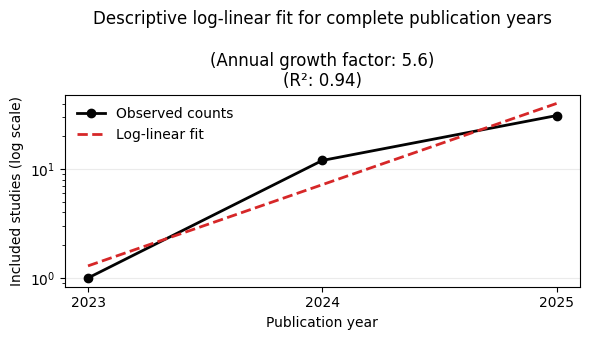

Figure saved to /Users/mafaldasavelho/Documents/Faculty/Papers/SLR/llms_for_xai_lit_review/notebooks/data/processed/loglinear_publication_trend.png


In [12]:
import matplotlib.pyplot as plt
from pathlib import Path

# Counts for the complete publication years represented in the included corpus.
annual_counts = pd.Series({2023: 1, 2024: 12, 2025: 31}, name='included_studies')
years = annual_counts.index.to_numpy(dtype=float)
counts = annual_counts.to_numpy(dtype=float)
year_index = years - years.min()

# log(count) = intercept + slope * year_index
slope, intercept = np.polyfit(year_index, np.log(counts), deg=1)
fitted_log_counts = intercept + slope * year_index
fitted_counts = np.exp(fitted_log_counts)
r_squared = 1 - (
    np.sum((np.log(counts) - fitted_log_counts) ** 2)
    / np.sum((np.log(counts) - np.mean(np.log(counts))) ** 2)
)
annual_growth_factor = np.exp(slope)

trend_summary = pd.DataFrame({
    'Year': years.astype(int),
    'Observed studies': counts.astype(int),
    'Fitted studies': fitted_counts,
})
display(trend_summary)
print(f'Annual multiplicative growth factor: {annual_growth_factor:.1f}')
print(f'R² on the log scale: {r_squared:.2f}')
print('This is a descriptive fit based on three observations; no inferential test is reported.')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(years, counts, marker='o', linewidth=2, color="#030303", label='Observed counts')
ax.plot(years, fitted_counts, linestyle='--', linewidth=2, color='#d62728', label='Log-linear fit')
ax.set_yscale('log')
ax.set_xticks(years)
ax.set_xlabel('Publication year')
ax.set_ylabel('Included studies (log scale)')
ax.set_title('Descriptive log-linear fit for complete publication years\n\n(Annual growth factor: 5.6)\n(R²: 0.94)')
ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()

trend_figure_path = Path(data_dir) / 'processed' / 'loglinear_publication_trend.png'
fig.savefig(trend_figure_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Figure saved to {trend_figure_path}')

#### Publication-year distribution with a descriptive log-linear fit
This adapts the original publication-year bar chart. The bars retain all observed counts, including the partial 2026 year, while the dashed line shows the descriptive fit based only on the complete years 2023, 2024, and 2025.

In [32]:
from pathlib import Path
from collections import Counter

import bibtexparser
import pandas as pd

bib_path = Path(data_dir) / "processed" / "included_studies.bib"

with bib_path.open(encoding="utf-8") as bib_file:
    entries = bibtexparser.load(bib_file).entries

year_records = []
missing_or_invalid_years = []

for entry in entries:
    raw_year = entry.get("year", "").strip()
    title = " ".join(entry.get("title", "").split())

    try:
        year = int(raw_year)
        year_records.append({"Year": year, "Title": title, "BibTeX key": entry["ID"]})
    except ValueError:
        missing_or_invalid_years.append(
            {"BibTeX key": entry["ID"], "Title": title, "Raw year": raw_year}
        )

years_df = pd.DataFrame(year_records).sort_values(["Year", "Title"])

print(f"Entries in BibTeX file: {len(entries)}")
print(f"Entries with a valid year: {len(years_df)}")

year_counts = years_df["Year"].value_counts().sort_index()
display(year_counts.rename("Number of included studies").to_frame())

if missing_or_invalid_years:
    print("\nEntries with missing or invalid years:")
    display(pd.DataFrame(missing_or_invalid_years))
else:
    print("\nAll entries have a valid publication year.")

# Optional: inspect the studies assigned to each year.
display(years_df)

Entries in BibTeX file: 50
Entries with a valid year: 50


,Number of included studies
Year,
2023,1
2024,12
2025,31
2026,6



All entries have a valid publication year.


,Year,Title,BibTeX key
44,2023,Explaining machine learning models with intera...,WOS:001037339300001
18,2024,Adaptive and transparent decision-making in au...,Hu20241579
17,2024,ArgMed-Agents: Explainable Clinical Decision R...,Hong2024
36,2024,Beyond Predictive Learning Analytics Modelling...,Susnjak2024452
6,2024,Explainable depression symptom detection in so...,Bao2024
2,2024,Explaining Graph Neural Networks with Large La...,10.18653/v1/2024.findings-emnlp.415
49,2024,Explingo: Explaining AI Predictions using Larg...,Zytek20241197
38,2024,From Feature Importance to Natural Language Ex...,Tekkesinoglu2024114
39,2024,Natural Language Explanation for Autonomous Na...,Trigg2024
35,2024,Natural Language Explanations for Suicide Risk...,Stern202412


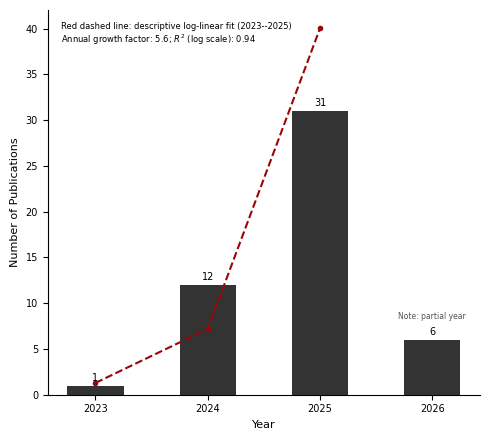

Combined figure saved to /Users/mafaldasavelho/Documents/Faculty/Papers/SLR/llms_for_xai_lit_review/notebooks/data/processed/publication_year_distribution_with_loglinear_fit.png


In [35]:
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import matplotlib.pyplot as plt

# Original Figure 2a style: a simple bar chart of observed annual counts.
year_counts = (
    years_df['Year']
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

complete_years = np.array([2023, 2024, 2025])
complete_counts = year_counts.reindex(complete_years).to_numpy(dtype=float)
complete_year_index = complete_years - complete_years.min()
fit_slope, fit_intercept = np.polyfit(complete_year_index, np.log(complete_counts), deg=1)
fit_counts = np.exp(fit_intercept + fit_slope * complete_year_index)
fit_r_squared = 1 - (
    np.sum((np.log(complete_counts) - (fit_intercept + fit_slope * complete_year_index)) ** 2)
    / np.sum((np.log(complete_counts) - np.mean(np.log(complete_counts))) ** 2)
)
fit_growth_factor = np.exp(fit_slope)

fig, ax = plt.subplots(figsize=(5.0, 4.5))
x_positions = np.arange(len(year_counts))
bars = ax.bar(x_positions, year_counts.values, color='#333333', width=0.5)

# The 2026 count covers only the period before the 18 January search date.
#if 2026 in year_counts.index:
#    partial_index = list(year_counts.index).index(2026)
#    bars[partial_index].set_facecolor('#333333')
#    bars[partial_index].set_edgecolor('#b3b3b3')
#    bars[partial_index].set_linewidth(0.6)
#    bars[partial_index].set_hatch('//')

ax.bar_label(bars, fontsize=7, padding=2)
fit_positions = [list(year_counts.index).index(year) for year in complete_years]
ax.plot(
    fit_positions,
    fit_counts,
    color="#9B0505",
    linestyle='--',
    linewidth=1.5,
    marker='o',
    markersize=3,
)

ax.set_xticks(x_positions, year_counts.index.astype(str))
ax.set_xlabel('Year', fontsize=8)
ax.set_ylabel('Number of Publications', fontsize=8)
ax.tick_params(axis='both', labelsize=7)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.text(
    0.03, 0.97,
    (
        'Red dashed line: descriptive log-linear fit (2023--2025)\n'
        f'Annual growth factor: {fit_growth_factor:.1f}; $R^2$ (log scale): {fit_r_squared:.2f}'
    ),
    transform=ax.transAxes,
    ha='left',
    va='top',
    fontsize=6,
    bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9, 'pad': 1.0},
)
if 2026 in year_counts.index:
    partial_index = list(year_counts.index).index(2026)
    ax.annotate(
        'Note: partial year',
        xy=(partial_index, year_counts.loc[2026]),
        xytext=(0, 15),
        textcoords='offset points',
        ha='center',
        fontsize=5.5,
        color='#555555',
    )
fig.tight_layout()

combined_figure_path = Path(data_dir) / 'processed' / 'publication_year_distribution_with_loglinear_fit.png'
fig.savefig(combined_figure_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Combined figure saved to {combined_figure_path}')

#### Calculating Herfindahl-Hirschman Index (HHI):

In [38]:
from collections import Counter
from pathlib import Path
import re

import bibtexparser

bib_path = Path(data_dir) / "processed" / "included_studies.bib"

with bib_path.open(encoding="utf-8") as bib_file:
    entries = bibtexparser.load(bib_file).entries

assert len(entries) == 50, f"Expected 50 studies, found {len(entries)}."

# Normalization mapping for abbreviations and casing inconsistencies
VENUE_NORMALIZATION = {
    "acm trans. inf. syst.": "ACM Transactions on Information Systems",
    "acm transactions on information systems": "ACM Transactions on Information Systems",
    "nature machine intelligence": "Nature Machine Intelligence",
}

def get_venue(entry):
    venue = entry.get("journal") or entry.get("booktitle")
    if not venue:
        return None
    
    # Strip whitespace/newlines and curly braces sometimes left by bibtex
    cleaned = re.sub(r"\s+", " ", venue).strip().strip("{}")
    
    # Standardize known variations/abbreviations
    return VENUE_NORMALIZATION.get(cleaned.lower(), cleaned)

venues = [get_venue(entry) for entry in entries]
missing_venues = [entry["ID"] for entry, venue in zip(entries, venues) if venue is None]

assert not missing_venues, f"Missing venue information: {missing_venues}"

venue_counts = Counter(venues)
total_studies = sum(venue_counts.values())

hhi = sum((count / total_studies) ** 2 for count in venue_counts.values())
largest_venue, largest_count = venue_counts.most_common(1)[0]

print(f"Number of distinct venues: {len(venue_counts)}")
print(f"HHI: {hhi:.3f}")
print(f"Effective number of venues (1 / HHI): {1 / hhi:.1f}")
print(
    f"Largest venue: {largest_venue} "
    f"({largest_count}/{total_studies}; {largest_count / total_studies:.1%})"
)
print(f"HHI on the conventional 0--10,000 scale: {hhi * 10_000:.0f}")

print("\nVenue distribution:")
for venue, count in venue_counts.most_common():
    print(f"{count:>2}  {venue}")

Number of distinct venues: 37
HHI: 0.034
Effective number of venues (1 / HHI): 29.8
Largest venue: CEUR Workshop Proceedings (4/50; 8.0%)
HHI on the conventional 0--10,000 scale: 336

Venue distribution:
 4  CEUR Workshop Proceedings
 3  IEEE Access
 2  ACM Transactions on Information Systems
 2  Machine Learning
 2  Applied Sciences (Switzerland)
 2  Health Information Science and Systems
 2  Proceedings - 2024 IEEE International Conference on Big Data, BigData 2024
 2  Communications in Computer and Information Science
 2  PeerJ Computer Science
 2  CIKM 2025 - Proceedings of the 34th ACM International Conference on Information and Knowledge Management
 1  Proceedings of the 30th International Conference on Intelligent User Interfaces
 1  Findings of the Association for Computational Linguistics: EMNLP 2024
 1  UMAP 2025 - Proceedings of the 33rd ACM Conference on User Modeling, Adaptation and Personalization
 1  IEEE Transactions on Network Science and Engineering
 1  Data and Knowl